[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/allusson/event-perception/blob/main/demo/event_camera_demo.ipynb)

# Event Cameras: a Hands-On Introduction

To run it in Colab: open the link above, then File > Save a copy in Drive to edit the TODOs.

An event camera has no shutter and no frames. Each pixel works on its own and reports an **event** whenever the log brightness it sees has changed by a fixed threshold $c$ since its last event. Each event is a tuple $(x, y, t, p)$: pixel position, a timestamp with microsecond resolution, and a polarity $p = +1$ (ON, brighter) or $-1$ (OFF, darker). Pixel $\mathbf{x} = (x, y)$ fires its $k$-th event at time $t_k$ when

$$\log I(\mathbf{x}, t_k) - \log I(\mathbf{x}, t_k - \Delta t_k) = p_k\, c$$

$I$: brightness at the pixel, $\Delta t_k$: time since that pixel's previous event, $p_k \in \{+1, -1\}$: polarity, $c$: contrast threshold (about 10 to 30 % brightness change).

Plots in this notebook use **red = ON (brighter), blue = OFF (darker)**.

**Equipment for the session**

- DAVIS346 event camera and its USB cable
- Laptop with DV (iniVation) installed
- Digilent Analog Discovery 2 (AD2) with WaveForms
- Breadboard and jumper wires
- One 5 mm LED
- One 1 kΩ resistor (330 Ω for a brighter LED; the AD2 waveform output is meant for signals, so keep the current to a few mA)

**Before the session:** download the star data for Part 4 (about 430 MB): `python scripts/download_data.py stars --star-sequences 3`.

## Setup

Run this cell first. On Colab it clones the repo, installs it and downloads the star data.

In [1]:
import os, sys
if "google.colab" in sys.modules:
    REPO = "/content/event-perception"
    if not os.path.exists(REPO):
        !git clone https://github.com/allusson/event-perception.git {REPO}
    %cd {REPO}
    !pip install -q -e .
    sys.path.insert(0, REPO)
    if not os.path.exists("data/stars/Sequence3.csv"):
        print("Downloading the star data for Part 4 (about 430 MB), this takes a few minutes...")
        !python scripts/download_data.py stars --star-sequences 3
else:
    # local: assumes `pip install -e .` was run from the repo root
    os.chdir(os.path.dirname(os.path.abspath("")) if os.path.basename(os.getcwd()) == "demo" else os.getcwd())

import numpy as np
import matplotlib.pyplot as plt

from evcam.io import load_aedat4
from evcam.frequency import busiest_roi, event_rate_spectrum
from evcam.representations import event_image
from evcam.viz import show_events


def draw_roi(ax, roi, color="k"):
    x0, y0, x1, y1 = roi
    ax.add_patch(plt.Rectangle((x0, y0), x1 - x0, y1 - y0, fill=False, ec=color, lw=1.5))

Cloning into '/content/event-perception'...
remote: Enumerating objects: 273, done.
remote: Counting objects: 100% (54/54), done.
remote: Compressing objects: 100% (37/37), done.
remote: Total 273 (delta 19), reused 42 (delta 17), pack-reused 219 (from 1)
Receiving objects: 100% (273/273), 46.50 MiB | 16.24 MiB/s, done.
Resolving deltas: 100% (143/143), done.
/content/event-perception
  Installing build dependencies ... done
  Checking if build backend supports build_editable ... done
  Getting requirements to build editable ... done
  Preparing editable metadata (pyproject.toml) ... done
  Building editable for evcam (pyproject.toml) ... done
Stars [3] -> data/stars
  download adelaide_event_star_tracking_dataset.zip
######################################################################## 100.0%
  unzip    CameraMatrix
  unzip    ReadMe
  unzip    Sequence3.csv
  unzip    Sequence3_attitudes
done: ['CameraMatrix', 'ReadMe', 'Sequence3.csv', 'Sequence3_attitudes', 'adelaide_event_star_

## Part 1. DV live view (no code)

Connect the DAVIS346, open DV and work through this list. The point is to build intuition for what events are before looking at any data.

- [ ] **Open the event visualizer and the grayscale frames side by side.** The DAVIS346 also has a normal (APS) frame sensor on the same pixels, so the two views can be compared directly.
- [ ] **Hold everything still.** The event view goes nearly blank: no brightness change, no events (the few left are sensor noise).
- [ ] **Wave a hand.** Events appear only at the moving edges, where brightness changes; flat regions of the hand stay silent.
- [ ] **Switch a lamp on in view.** Everything that gets brighter fires ON events, so this shows which color DV uses for ON. DV's colors may differ from this notebook's red/blue.
  DV's ON color: ______________ &nbsp;&nbsp; DV's OFF color: ______________
- [ ] **Move fast.** The grayscale frames blur (each integrates light over its exposure time), while the events stay sharp (each is a timestamped change).
- [ ] **Point at a bright lamp or window and a dark area at once.** The frames saturate in the bright part or go black in the dark part, while events still respond in both: each pixel works on a log scale relative to its own last level (high dynamic range, about 120 dB vs about 55 dB for the frames).
- [ ] **Record.** Add an `output_file` module, wire the camera's `events` and `frames` outputs into it, set the output folder, then start and stop the recording.
  Wire the camera's own `frames` output, not an Accumulator: the Accumulator draws images from the events, and recording it loses the real frames.

## Part 2. Build the LED circuit (no code)

The AD2 will blink an LED at a known frequency $f$, so the event camera's measurement in Part 3 can be checked against the truth.

**Wiring**

```
AD2 W1 (waveform out) ──[ 1 kΩ ]──► LED anode (long leg)
                                    LED cathode (short leg, flat side of the rim) ──► AD2 ground (any ⏚ pin)
```

| From | To |
|---|---|
| AD2 W1 (waveform generator 1) | one end of the resistor |
| other end of the resistor | LED anode (long leg) |
| LED cathode (short leg, flat side) | AD2 ground (any ⏚ pin) |

The resistor limits the current (Ohm's law): $I = (V - V_\text{LED}) / R$, e.g. $(5 - 2)\ \text{V} / 1\ \text{k}\Omega = 3$ mA.

**WaveForms, Wavegen settings:** Type Square, Frequency $f$, Amplitude 2.5 V, Offset 2.5 V. The output then swings from 0 to 5 V, so the LED is fully off, then fully on.

**Record**

1. Set $f$ = 50 Hz and start the Wavegen.
2. Point the DAVIS at the LED from close up (10 to 20 cm), and check in DV that the LED blinks in the event view.
3. Record 3 s to `demo/data/demo_led.aedat4`.
4. Optional: repeat at 500 Hz (save it under another name and point `RECORDING` below at it).

In [2]:
# Optional, Colab only: upload your own recording from Part 2.
# Uncomment the lines below, run the cell and pick the .aedat4 file. Locally this cell does nothing.
if "google.colab" in sys.modules:
    os.makedirs("demo/data", exist_ok=True)
    # from google.colab import files
    # uploaded = files.upload()
    # name, content = next(iter(uploaded.items()))
    # open("demo/data/demo_led.aedat4", "wb").write(content)
    # print(f"saved {name} as demo/data/demo_led.aedat4")

## Part 3. Frequency from events

A frame camera samples brightness at its frame rate; an event camera reports each change with a microsecond timestamp. So the blinking of the LED shows up as bursts in the event rate, and the frequency of those bursts is the LED frequency. This part reuses the method of notebook 04: count ON events in a small region around the LED in 50 µs bins and take the spectrum of that count.

In [3]:
RECORDING = "demo/data/demo_led.aedat4"            # recorded in Part 2
FALLBACK = "demo/data/led_0050hz.aedat4"           # 50 Hz LED recorded for notebook 04
F_TRUE = 50                                        # Hz, set on the Wavegen

if os.path.exists(RECORDING):
    path = RECORDING
    print(f"Using the demo recording {path}")
else:
    path = FALLBACK
    print(f"{RECORDING} not found, using the fallback {path}")

# notebook 04 settings
EVENTS_PER_CYCLE = 1      # the LED flashes once per cycle
POLARITY = 1              # ON events only
BIN_US = 50               # event-rate bin, microseconds
T_START_S = 0.5
WINDOW_S = 2.0

events, frames, sensor_size = load_aedat4(path)
shape = (sensor_size[1], sensor_size[0])
t0 = int(T_START_S * 1e6)
t1 = min(t0 + int(WINDOW_S * 1e6), int(events["t"][-1]))
WINDOW_S = (t1 - t0) / 1e6                         # shorter if the recording is short
win = events[(events["t"] >= t0) & (events["t"] < t1)]
roi = busiest_roi(win, shape)
print(f"{len(events):,} events over {events['t'][-1] / 1e6:.2f} s, analysis window {WINDOW_S:.2f} s, ROI {roi}")

demo/data/demo_led.aedat4 not found, using the fallback demo/data/led_0050hz.aedat4
530,804 events over 7.34 s, analysis window 2.00 s, ROI (148, 110, 188, 150)


**1. Event image.** ON minus OFF count per pixel over 50 ms. The LED is the busy blob; the black square is the region (ROI) chosen automatically as the busiest 40×40 pixels.

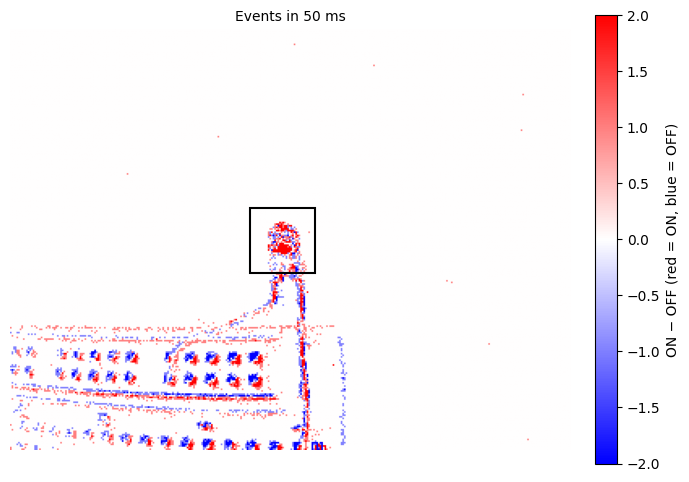

In [4]:
SPAN_US = 50_000
m = (events["t"] >= t0) & (events["t"] < t0 + SPAN_US)

fig, ax = plt.subplots(figsize=(7, 5))
show_events(ax, event_image(events[m], sensor_size), title=f"Events in {SPAN_US / 1000:.0f} ms")
draw_roi(ax, roi)
ax.axis("off"); plt.tight_layout(); plt.show()

**2. Event rate in the ROI.** Number of ON events per 50 µs bin over 100 ms. Each LED flash is a burst of events; at 50 Hz there should be 5 bursts.

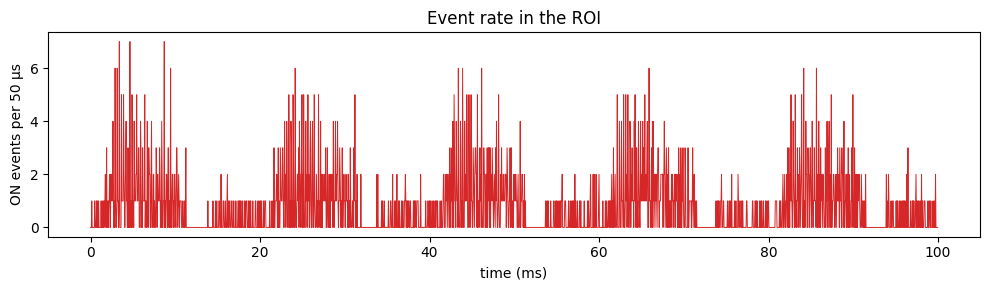

In [5]:
SPAN_US = 100_000
x0, y0, x1, y1 = roi
m = ((events["t"] >= t0) & (events["t"] < t0 + SPAN_US) & (events["p"] == POLARITY)
     & (events["x"] >= x0) & (events["x"] < x1) & (events["y"] >= y0) & (events["y"] < y1))
n_bins = SPAN_US // BIN_US
counts = np.bincount((events["t"][m] - t0) // BIN_US, minlength=n_bins)[:n_bins]

plt.figure(figsize=(10, 3))
plt.plot(BIN_US * np.arange(n_bins) / 1000, counts, lw=0.7, color="tab:red")
plt.xlabel("time (ms)"); plt.ylabel(f"ON events per {BIN_US} µs")
plt.title("Event rate in the ROI"); plt.tight_layout(); plt.show()

**3. Spectrum.** `event_rate_spectrum` returns the power spectrum of that event count over the whole window: `freqs` (Hz) and `power`. A periodic signal appears as a sharp peak at its frequency.

**TODO 1:** pick the frequency of the strongest peak. Frequencies below 5 Hz (slow drift) are already left out of `freqs_band` and `power_band`.

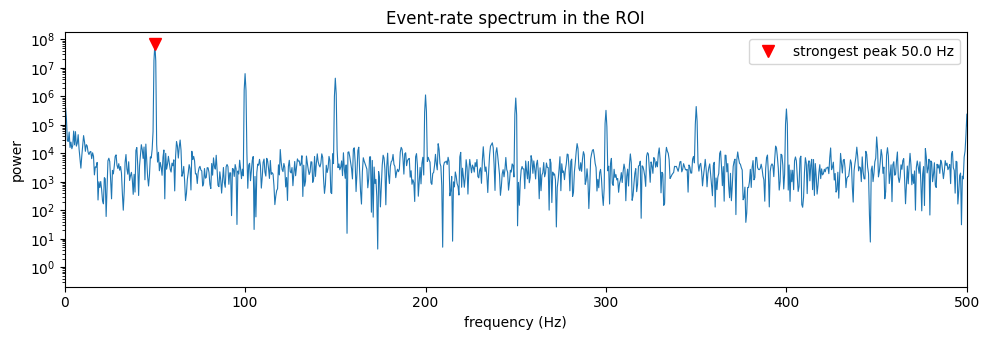

estimated LED frequency: 50.00 Hz (set on the Wavegen: 50 Hz)


In [12]:
freqs, power, f_lib = event_rate_spectrum(events, t0, t1, bin_us=BIN_US, roi=roi, polarity=POLARITY)
band = freqs >= 5.0
freqs_band, power_band = freqs[band], power[band]

# TODO 1: frequency of the strongest peak (use freqs_band, power_band and np.argmax)
#f_peak = freqs_band[np.argmax(power_band)]

if f_peak is ...:
    f_peak = freqs_band[np.argmax(power_band)]
    print("(TODO 1 left blank: using the solution)")
f_est = f_peak / EVENTS_PER_CYCLE

plt.figure(figsize=(10, 3.5))
plt.semilogy(freqs[1:], power[1:], lw=0.8)
plt.plot(f_peak, power_band.max(), "rv", ms=9, label=f"strongest peak {f_peak:.1f} Hz")
plt.xlim(0, 10 * f_peak); plt.xlabel("frequency (Hz)"); plt.ylabel("power")
plt.title("Event-rate spectrum in the ROI"); plt.legend(); plt.tight_layout(); plt.show()
print(f"estimated LED frequency: {f_est:.2f} Hz (set on the Wavegen: {F_TRUE} Hz)")

<details><summary>Solution</summary>

```python
f_peak = freqs_band[np.argmax(power_band)]
```
</details>

**4. Frequency resolution.** The spectrum of a window of length $T$ has one bin every $1/T$ Hz, so the strongest bin is only known to within that spacing. A longer window holds more cycles, and two frequencies that differ by less than $1/T$ only drift apart by a full cycle over a time longer than $T$, so they cannot be told apart.

**TODO 2:** fill in the bin spacing (frequency resolution) for a window of `WINDOW_S` seconds.

In [7]:
# TODO 2: frequency resolution (Hz) of a window of WINDOW_S seconds
resolution = 1 / WINDOW_S

if resolution is ...:
    resolution = 1 / WINDOW_S
    print("(TODO 2 left blank: using the solution)")

print(f"window {WINDOW_S:.2f} s -> resolution {resolution:.2f} Hz (bin spacing in the spectrum: {freqs[1]:.2f} Hz)")
print(f"estimate: {f_est:.2f} ± {resolution / 2:.2f} Hz")
print(f"notebook 04 refines the peak between bins: {f_lib / EVENTS_PER_CYCLE:.2f} Hz")

(TODO 2 left blank: using the solution)
window 2.00 s -> resolution 0.50 Hz (bin spacing in the spectrum: 0.50 Hz)
estimate: 50.00 ± 0.25 Hz
notebook 04 refines the peak between bins: 50.00 Hz


<details><summary>Solution</summary>

```python
resolution = 1 / WINDOW_S
```
</details>

**5. Beyond a frame camera.** A 30 fps camera samples brightness 30 times a second, so it cannot measure anything above 15 Hz (the Nyquist limit); a faster flicker is aliased or averaged out. The same spectrum on the five LED recordings of notebook 04 measures up to 3000 Hz:

In [8]:
FRAME_RATE = 30
LED_RECORDINGS = {f"demo/data/led_{f:04d}hz.aedat4": f for f in (10, 50, 500, 1000, 3000)}

print(f"{'true (Hz)':>10}{'events (Hz)':>14}{'error':>9}   30 fps camera (max {FRAME_RATE / 2:.0f} Hz)")
for p, f_true in LED_RECORDINGS.items():
    if not os.path.exists(p):
        print(f"{f_true:>10}{'SKIPPED: ' + p + ' not found':>40}")
        continue
    ev, _, size = load_aedat4(p)
    a, b = int(T_START_S * 1e6), int((T_START_S + 2.0) * 1e6)
    r = busiest_roi(ev[(ev["t"] >= a) & (ev["t"] < b)], (size[1], size[0]))
    f = event_rate_spectrum(ev, a, b, bin_us=BIN_US, roi=r, polarity=POLARITY)[2] / EVENTS_PER_CYCLE
    print(f"{f_true:>10}{f:>14.2f}{abs(f - f_true) / f_true:>9.2%}   {'yes' if f_true < FRAME_RATE / 2 else 'no'}")

 true (Hz)   events (Hz)    error   30 fps camera (max 15 Hz)
        10         10.00    0.05%   yes
        50         50.00    0.01%   no
       500        500.00    0.00%   no
      1000       1000.00    0.00%   no
      3000       2999.99    0.00%   no


## Part 4. Motion compensation on stars

The data (Chin et al., 2019) are stars shown on a screen and filmed by an event camera (DAVIS240C, 240×180) that rotates slowly. The stars move about 11 px/s, so a window of events is a set of short streaks: each star leaves a trail of events along its path. If the motion is known, each event can be moved back along it to where it was at a reference time $t_\text{ref}$, and the streaks collapse into points. Contrast maximization (Gallego et al., 2018) finds the motion as the one that makes this image of warped events sharpest. The same method is used in notebook 05.

52,892 events in 2.0 s


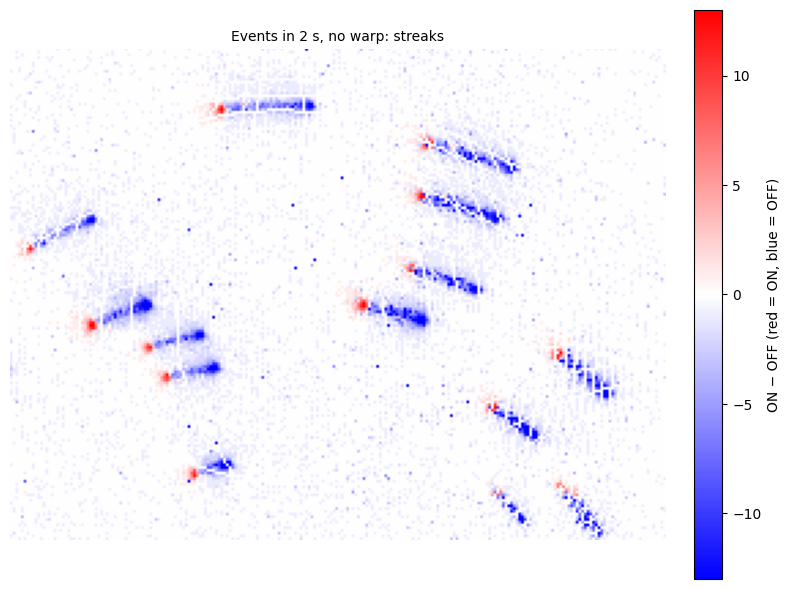

In [9]:
from evcam.io import load_star_sequence, crop_time, STAR_SHAPE
from evcam.cmax import iwe_from_coords, contrast

SEQ, T_START_S, WINDOW_S = 3, 5.0, 2.0      # notebook 05 settings
H, W = STAR_SHAPE
PAD = 50                                    # canvas margin so warped events stay in the image
canvas, origin = (H + 2 * PAD, W + 2 * PAD), (-PAD, -PAD)

try:
    star_events, _ = load_star_sequence(SEQ)
    HAVE_STARS = True
except FileNotFoundError:
    HAVE_STARS = False
    print(f"SKIPPED: star data not found. Run: python scripts/download_data.py stars --star-sequences {SEQ}")

if HAVE_STARS:
    ev = crop_time(star_events, int(T_START_S * 1e6), int(WINDOW_S * 1e6))
    x, y, t = ev["x"].astype(float), ev["y"].astype(float), ev["t"] / 1e6     # t in seconds
    t_ref = t[0]
    print(f"{len(ev):,} events in {WINDOW_S:.1f} s")
    fig, ax = plt.subplots(figsize=(8, 6))
    show_events(ax, event_image(ev, (W, H, 2)), title=f"Events in {WINDOW_S:.0f} s, no warp: streaks")
    ax.axis("off"); plt.tight_layout(); plt.show()

**TODO 3:** warp the events for a candidate image velocity $\mathbf{v} = (v_x, v_y)$ in px/s. An event at $(x_k, y_k)$ and time $t_k$ is moved back to where that point was at $t_\text{ref}$:

$$\mathbf{x}'_k = \mathbf{x}_k - \mathbf{v}\,(t_k - t_\text{ref})$$

Fill in `x_warped` and `y_warped` (`v[0]` is $v_x$, `v[1]` is $v_y$).

In [13]:
def warp(x, y, t, v, t_ref):
    # TODO 3: move each event back to t_ref along velocity v (px/s)
    x_warped = x - v[0] * (t - t_ref)
    y_warped = y - v[1] * (t - t_ref)

    if x_warped is ... or y_warped is ...:
        if not getattr(warp, "noted", False):
            print("(TODO 3 left blank: using the solution)")
            warp.noted = True
        x_warped = x - v[0] * (t - t_ref)
        y_warped = y - v[1] * (t - t_ref)
    return x_warped, y_warped


x_test, _ = warp(np.array([1.0]), np.array([1.0]), np.array([1.0]), (1.0, 1.0), 0.0)
print("warp check:", "ok" if np.allclose(x_test, 0.0) else f"expected x = 0, got {x_test}")

warp check: ok


<details><summary>Solution</summary>

```python
x_warped = x - v[0] * (t - t_ref)
y_warped = y - v[1] * (t - t_ref)
```
</details>

**Contrast landscape.** For each velocity on a grid, warp the events, build the image of warped events $H$ and compute its contrast, the variance of $H$. Sharp points give high variance, smeared streaks low variance; the best velocity is the maximum.

best velocity: (12, 3) px/s


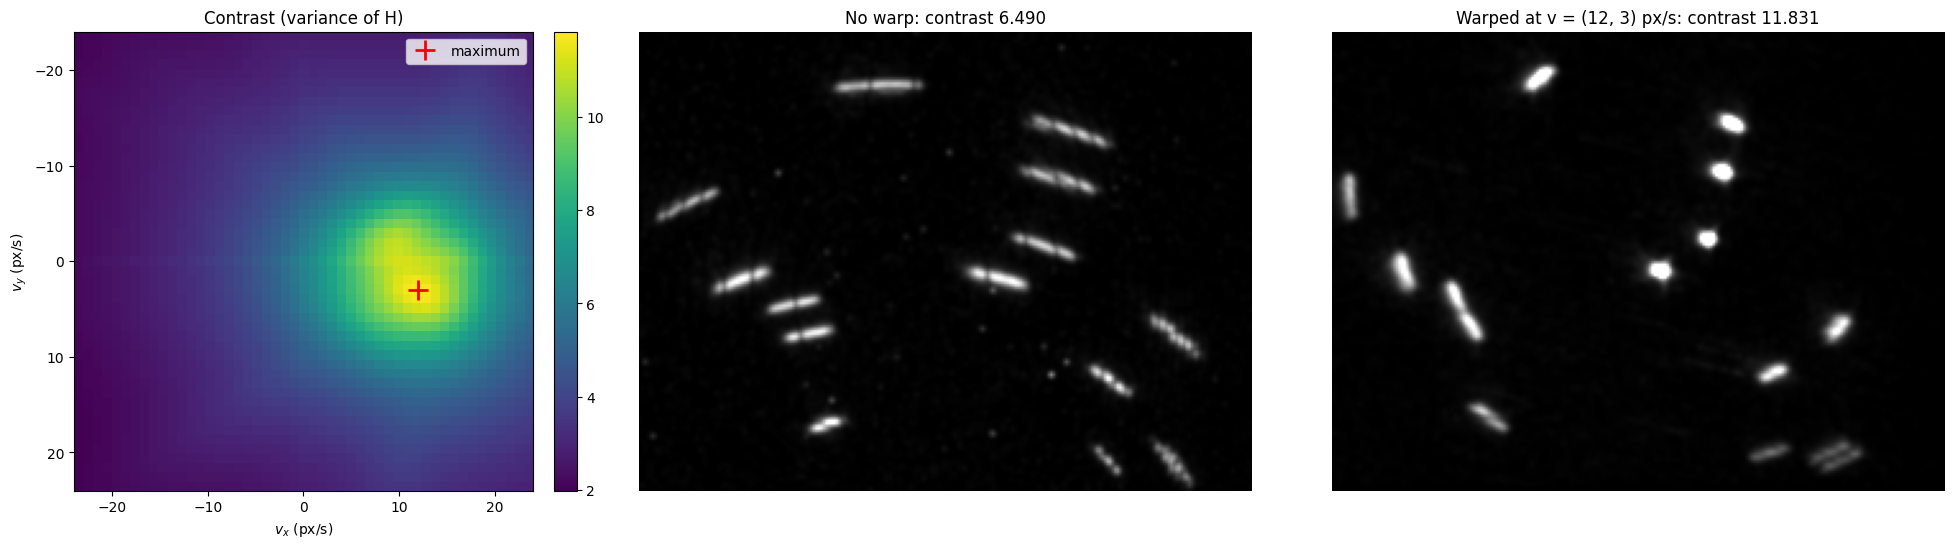

In [11]:
if HAVE_STARS:
    iwe_v = lambda v: iwe_from_coords(*warp(x, y, t, v, t_ref), canvas, origin)
    grid = np.arange(-24, 25, 1.0)                                    # px/s, as in notebook 05
    S = np.array([[contrast(iwe_v((vx, vy))) for vx in grid] for vy in grid])
    iy, ix = np.unravel_index(S.argmax(), S.shape)
    v_best = (grid[ix], grid[iy])
    print(f"best velocity: ({v_best[0]:.0f}, {v_best[1]:.0f}) px/s")

    img0, img1 = iwe_v((0, 0)), iwe_v(v_best)
    vmax = np.percentile(img1, 99.8)
    fig, ax = plt.subplots(1, 3, figsize=(20, 5.2), gridspec_kw={"width_ratios": [1, 1.25, 1.25]})
    im = ax[0].imshow(S, extent=[grid[0], grid[-1], grid[-1], grid[0]], cmap="viridis")
    ax[0].plot(*v_best, "r+", ms=14, mew=2, label="maximum")
    ax[0].set_xlabel("$v_x$ (px/s)"); ax[0].set_ylabel("$v_y$ (px/s)"); ax[0].set_title("Contrast (variance of H)")
    ax[0].legend(); plt.colorbar(im, ax=ax[0], fraction=0.046, pad=0.04)
    for a, img, name in ((ax[1], img0, "No warp"), (ax[2], img1, f"Warped at v = ({v_best[0]:.0f}, {v_best[1]:.0f}) px/s")):
        a.imshow(img[PAD:-PAD, PAD:-PAD], cmap="gray", vmin=0, vmax=vmax)
        a.set_title(f"{name}: contrast {contrast(img):.3f}"); a.axis("off")
    plt.tight_layout(); plt.show()

The streaks collapse into points. No frames and no feature matching were used: the motion comes from the events alone. (The true motion is a rotation, so one velocity cannot sharpen every star equally; notebook 05 fits the rotation as well.)

## Part 5. Wrap-up

An event camera reports only changes, so a still scene is silent and a moving edge is a stream of events. Its microsecond timing measured an LED blinking at up to 3000 Hz, far above what a 30 fps camera can see, and warping the events themselves recovered the motion of a star field without any frames. More in the repo: notebook 04 (frequency estimation), 05 (contrast maximization on the stars, with a rotation model), 08 (rotation speed of a spinner from events) and 09 (event synthesis with diffusion).

## References

1. P. Lichtsteiner, C. Posch, T. Delbruck, "A 128×128 120 dB 15 µs Latency Asynchronous Temporal Contrast Vision Sensor", IEEE Journal of Solid-State Circuits 43(2), 2008 (event pixel).
2. C. Brandli, R. Berner, M. Yang, S.-C. Liu, T. Delbruck, "A 240×180 130 dB 3 µs Latency Global Shutter Spatiotemporal Vision Sensor", IEEE Journal of Solid-State Circuits 49(10), 2014 (DAVIS sensor).
3. G. Gallego, H. Rebecq, D. Scaramuzza, "A Unifying Contrast Maximization Framework for Event Cameras, with Applications to Motion, Depth, and Optical Flow Estimation", CVPR 2018 (contrast maximization).
4. T.-J. Chin, S. Bagchi, A. Eriksson, A. van Schaik, "Star Tracking Using an Event Camera", CVPR Workshops 2019 (star data).